# 2016〜2026年 衆議院予算委員会 名詞限定クラスタリング

普通名詞・固有名詞だけからTF-IDFを作り、68,948発言を共通の特徴空間で10クラスタに分類します。既存の名詞・動詞・形容詞版とは別に結果を保存します。

In [1]:
from pathlib import Path
import os
import sys

ROOT = Path.cwd()
if not (ROOT / 'cleaned').exists():
    ROOT = ROOT.parent
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.matplotlib'))
Path(os.environ['MPLCONFIGDIR']).mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
from matplotlib import font_manager
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(ROOT))
from clustering_2016 import (
    FIXED_K, RANDOM_STATE, apply_manual_labels, cluster_details, compare_k,
    export_results, load_input, reduce_dimensions, tokenize_ja_nouns,
    vectorize_nouns,
)

sns.set_theme(style='whitegrid')
mac_font_paths = list(Path('/System/Library/Fonts').glob('*角*W3.ttc'))
if not mac_font_paths:
    raise FileNotFoundError('macOSのヒラギノ角ゴシック W3が見つかりません')
font_manager.fontManager.addfont(str(mac_font_paths[0]))
MAC_JAPANESE_FONT = font_manager.FontProperties(fname=str(mac_font_paths[0])).get_name()
plt.rcParams['font.family'] = MAC_JAPANESE_FONT
plt.rcParams['axes.unicode_minus'] = False
OUTPUT_DIR = ROOT / 'analysis/clustering_2016_2026_nouns'
EXPECTED_BY_YEAR = {2016: 5928, 2017: 6283, 2018: 7434, 2019: 5985, 2020: 8056, 2021: 6269, 2022: 6451, 2023: 5744, 2024: 5896, 2025: 7449, 2026: 3453}
print(f'Matplotlib font: {MAC_JAPANESE_FONT} ({mac_font_paths[0]})')
RANDOM_STATE

Matplotlib font: Hiragino Sans (/System/Library/Fonts/ヒラギノ角ゴシック W3.ttc)


42

## 1. 年別入力の読込・検証

In [2]:
frames = [
    load_input(ROOT / f'cleaned/speeches_{year}.jsonl', expected_rows=count)
    for year, count in EXPECTED_BY_YEAR.items()
]
df = pd.concat(frames, ignore_index=True, verify_integrity=True)
assert len(df) == 68948
assert df['speechID'].is_unique
assert df['nameOfMeeting'].eq('予算委員会').all()
assert set(df['year']) == set(EXPECTED_BY_YEAR)
year_counts_input = df.groupby('year', as_index=False).agg(speeches=('speechID', 'size'), speakers=('speaker', 'nunique'))
display(year_counts_input)
display(pd.Series({'rows': len(df), 'unique_speech_ids': df['speechID'].nunique(), 'years': df['year'].nunique(), 'review_flagged': int(df['review_flags'].map(bool).sum())}).to_frame('value'))

,year,speeches,speakers
0,2016,5928,211
1,2017,6283,218
2,2018,7434,235
3,2019,5985,196
4,2020,8056,228
5,2021,6269,251
6,2022,6451,255
7,2023,5744,228
8,2024,5896,279
9,2025,7449,374


,value
rows,68948
unique_speech_ids,68948
years,11
review_flagged,5141


## 2. 普通名詞・固有名詞のTF-IDFと次元削減

レビュー用フラグやラベルは使わず、`speech_cleaned` の本文だけを特徴量化します。

In [3]:
source_df = df.copy()
vectorizer, tfidf, keep_mask = vectorize_nouns(source_df)
zero_vector_records = source_df.loc[~keep_mask].copy()
zero_vector_records.loc[:, 'exclusion_reason'] = 'zero_vector_after_tfidf'
df = source_df.loc[keep_mask].copy().reset_index(drop=True)
assert len(df) + len(zero_vector_records) == len(source_df)
assert set(df['speechID']).isdisjoint(set(zero_vector_records['speechID']))
feature_names = vectorizer.get_feature_names_out()
assert not {'発言短文', '低情報発言'} & set(feature_names)
unverified_features = set(feature_names)
for text in source_df['speech_cleaned']:
    noun_tokens = tokenize_ja_nouns(text)
    unverified_features.difference_update(noun_tokens)
    unverified_features.difference_update(' '.join(pair) for pair in zip(noun_tokens, noun_tokens[1:]))
assert not unverified_features, f'本文の名詞列から生成されない特徴があります: {sorted(unverified_features)[:10]}'
svd, reduced = reduce_dimensions(tfidf)
print(f'TF-IDF: {tfidf.shape[0]:,} rows × {tfidf.shape[1]:,} features')
print(f'SVD explained variance: {svd.explained_variance_ratio_.sum():.1%}')
print(f'Zero vectors excluded: {len(zero_vector_records):,}')
display(zero_vector_records[['speechID', 'date', 'year', 'speaker', 'speech_cleaned', 'exclusion_reason']])

TF-IDF: 67,882 rows × 20,000 features
SVD explained variance: 11.7%
Zero vectors excluded: 1,066


,speechID,date,year,speaker,speech_cleaned,exclusion_reason
32,119205261X00520161012_038,2016-10-12,2016,西村康稔,ありがとうございました。終わります。,zero_vector_after_tfidf
43,119205261X00520161012_050,2016-10-12,2016,赤羽一嘉,どうもありがとうございました。 以上で終わります。,zero_vector_after_tfidf
117,119205261X00520161012_148,2016-10-12,2016,井出庸生,現存しないものが今あるかないかというところを、ないと言い切れますか。,zero_vector_after_tfidf
136,119205261X00520161012_172,2016-10-12,2016,山尾志桜里,ちょっと静かにしていただけますか。,zero_vector_after_tfidf
262,119205261X00520161012_319,2016-10-12,2016,高橋千鶴子,どこですか。,zero_vector_after_tfidf
...,...,...,...,...,...,...
68750,122105261X00220260227_132,2026-02-27,2026,岡本三成,ありがとうございました。 終わります。,zero_vector_after_tfidf
68780,122105261X00220260227_165,2026-02-27,2026,長妻昭,総理、いかがですか。,zero_vector_after_tfidf
68816,122105261X00220260227_202,2026-02-27,2026,山本香苗,総理、いかがでしょうか。,zero_vector_after_tfidf
68822,122105261X00220260227_208,2026-02-27,2026,山本香苗,総理、いかがでしょうか。,zero_vector_after_tfidf


## 3. KMeans（10クラスタ固定）

In [4]:
scores, models = compare_k(reduced, candidates=[FIXED_K])
best_k = FIXED_K
model = models[best_k]
print(f'Fixed k={best_k}')
display(scores.style.format({'silhouette': '{:.4f}', 'inertia': '{:,.1f}'}))

Fixed k=10


,k,silhouette,inertia,smallest_cluster,largest_cluster
0,10,0.0340,"55,405.4",3076,23454


## 4. クラスタの解釈

,cluster,provisional_label,count,ratio,top_terms,representative_speech_ids
0,0,先程・答え・報告,23454,34.6%,先程 | 答え | 報告 | 事実 | 承知 | 判断 | 認識 | 委員会 | 文書 | 委員長 | 検討 | 理解,119305261X00320170127_069 | 119305261X01520170224_096 | 119305261X00820170207_261 | 119605261X01320180219_254 | 119605261X01320180219_248
1,1,感染・接種・ワクチン,4036,5.9%,感染 | 接種 | ワクチン | 検査 | 医療 | 対策 | 状況 | 体制 | 拡大 | 感染 拡大 | コロナ | 感染症,120805261X01020220204_002 | 120805261X00820220202_030 | 120405261X01120210216_002 | 120805261X00220220124_133 | 120805261X00220220124_110
2,2,議論・政治・自民党,6268,9.2%,議論 | 政治 | 自民党 | 議員 | 国民 | 資金 | 政治 資金 | 政党 | 選挙 | 総裁 | 政策 | 団体,121605261X00120241205_209 | 121305261X01720240422_054 | 121305261X00720240209_294 | 121305261X01420240226_084 | 119205261X00420161004_191
3,3,経済・賃金・政策,4430,6.5%,経済 | 賃金 | 政策 | 成長 | 物価 | 賃上げ | 企業 | 財政 | 投資 | 金融 | 金利 | 日本,121905261X00720251210_380 | 121705261X00220250131_049 | 120805261X01620220218_270 | 119005261X01220160215_121 | 121305261X01420240226_312
4,4,支援・地域・取り組み,8286,12.2%,支援 | 地域 | 取り組み | 事業 | 自治体 | 状況 | 地方 | 活用 | 整備 | 対策 | 災害 | 事業者,119805261X01020190220_551 | 120105261X01320200218_413 | 119005261X01420160218_162 | 121305261X01220240221_292 | 119805261X01020190220_553
5,5,予算・年度・補正,3705,5.5%,予算 | 年度 | 補正 | 補正 予算 | 令和 | 令和 年度 | 計上 | 予算 委員会 | 基金 | 委員会 | 審議 | 対策,122105261X00420260303_304 | 122105261X01120260313_074 | 122105261X00220260227_078 | 121205261X00320231030_307 | 122105261X00520260304_108
6,6,調査・結果・調査 結果,3076,4.5%,調査 | 結果 | 調査 結果 | 委員会 | 報告 | 統計 | 調査 調査 | 事案 | データ | 公表 | 先程 | 第三者,119305261X00420170201_071 | 119805261X00220190204_294 | 119605261X01220180215_051 | 120405261X01420210219_320 | 119305261X00320170127_246
7,7,負担・制度・子供,6018,8.9%,負担 | 制度 | 子供 | 財源 | 子育て | 軽減 | 社会保障 | 支援 | 給付 | 教育 | 無償化 | 消費税,120105261X00220200127_057 | 119805261X01320190225_304 | 119805261X00420190208_129 | 121905261X00720251210_247 | 122105261X00820260309_121
8,8,安全・安全 保障・保障,3523,5.2%,安全 | 安全 保障 | 保障 | 自衛隊 | 防衛 | 我が国 | 攻撃 | 米軍 | 基地 | ミサイル | 能力 | 日米,121105261X01120230215_012 | 119805261X01020190220_048 | 119305261X00720170206_010 | 121005261X00820221129_004 | 119305261X01120170214_184
9,9,日本・アメリカ・世界,5086,7.5%,日本 | アメリカ | 世界 | 会談 | 交渉 | 我が国 | 日米 | 首脳 | 国際 | 中国 | 米国 | トランプ大統領,121705261X00220250131_033 | 121605261X00320241210_036 | 120405261X00420210204_339 | 121705261X02120250414_129 | 121705261X00720250207_023


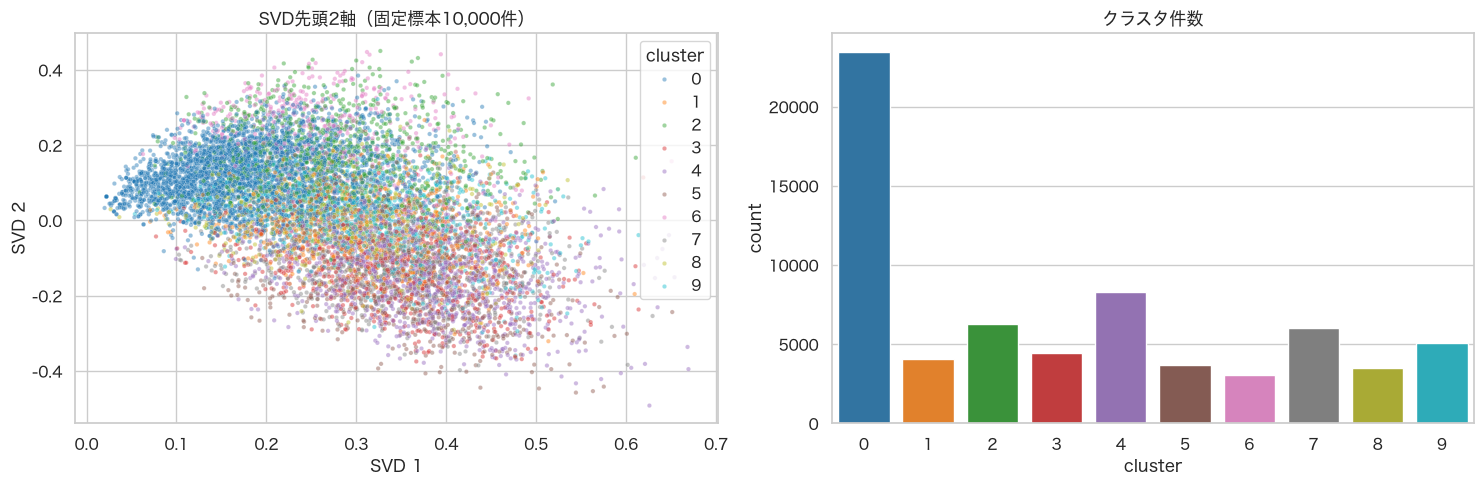

In [5]:
assignments, summary = cluster_details(df, tfidf, reduced, vectorizer, model)
display(summary.style.format({'ratio': '{:.1%}'}))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_sample = assignments.sample(n=min(10000, len(assignments)), random_state=RANDOM_STATE)
plot_idx = plot_sample.index.to_numpy()
sns.scatterplot(x=reduced[plot_idx, 0], y=reduced[plot_idx, 1], hue=plot_sample['cluster'], palette='tab10', s=10, alpha=.45, legend='full', ax=axes[0])
axes[0].set(title='SVD先頭2軸（固定標本10,000件）', xlabel='SVD 1', ylabel='SVD 2')
sns.barplot(data=summary, x='cluster', y='count', hue='cluster', palette='tab10', legend=False, ax=axes[1])
axes[1].set_title('クラスタ件数')
plt.tight_layout();

In [6]:
for cluster_id in summary['cluster']:
    row = summary.loc[summary['cluster'].eq(cluster_id)].iloc[0]
    members = assignments.loc[assignments['cluster'].eq(cluster_id)]
    representatives = members.nsmallest(5, 'centroid_distance')[['speechID', 'date', 'year', 'speaker', 'speech_cleaned', 'centroid_distance']]
    top_speakers = members['speaker'].value_counts().head(5).rename_axis('speaker').reset_index(name='count')
    print(f"\nCluster {cluster_id}: {row['provisional_label']} ({row['count']:,}件)")
    print(f"特徴語: {row['top_terms']}")
    display(top_speakers, representatives)


Cluster 0: 先程・答え・報告 (23,454件)
特徴語: 先程 | 答え | 報告 | 事実 | 承知 | 判断 | 認識 | 委員会 | 文書 | 委員長 | 検討 | 理解


,speaker,count
0,安倍晋三,1384
1,後藤祐一,774
2,岸田文雄,756
3,今井雅人,695
4,菅義偉,603


,speechID,date,year,speaker,speech_cleaned,centroid_distance
11487,119305261X00320170127_069,2017-01-27,2017,小川淳也,改めてお調べいただきたいと思いますけれども、恐らく、推測ですが、文教協会の中でこのあっせん業...,0.870116
7513,119305261X01520170224_096,2017-02-24,2017,玉木雄一郎,いや、どう考えてもおかしいですよ。 私、きのうの昼、実際に工事に携わった方にお話を伺いました...,0.877832
9832,119305261X00820170207_261,2017-02-07,2017,今井雅人,資料の最後から二番目に最高裁の四十七年の判決がありますけれども、これは、どれぐらいの処分をす...,0.878862
15581,119605261X01320180219_254,2018-02-19,2018,柚木道義,そうじゃないんですよ、国家公安委員長。検察審査会自体も、本当に議事録、詳細をごらんいただけれ...,0.879988
15575,119605261X01320180219_248,2018-02-19,2018,柚木道義,これは、今大臣は実は正直に言われたんですよ。 わからないんですよ、個々によるということは、実...,0.881586



Cluster 1: 感染・接種・ワクチン (4,036件)
特徴語: 感染 | 接種 | ワクチン | 検査 | 医療 | 対策 | 状況 | 体制 | 拡大 | 感染 拡大 | コロナ | 感染症


,speaker,count
0,加藤勝信,332
1,田村憲久,208
2,菅義偉,186
3,後藤茂之,184
4,岸田文雄,183


...

,speaker,count
0,岸田文雄,304
1,安倍晋三,229
2,赤嶺政賢,147
3,小野寺五典,115
4,稲田朋美,109


,speechID,date,year,speaker,speech_cleaned,centroid_distance
48258,121105261X01120230215_012,2023-02-15,2023,石破茂,おはようございます。自由民主党の石破茂であります。 総理、その後、お具合はいかがですか。私も...,0.617893
22037,119805261X01020190220_048,2019-02-20,2019,安倍晋三,「いずも」型護衛艦における航空機の運用は、広大な太平洋を含む我が国の海の守りについて、自衛隊...,0.631224
10025,119305261X00720170206_010,2017-02-06,2017,稲田朋美,那覇空港を使用している航空自衛隊那覇基地は、南西地域における唯一の航空自衛隊の航空基地であり...,0.654197
39261,121005261X00820221129_004,2022-11-29,2022,國場幸之助,自由民主党の國場幸之助です。 本日は、貴重な質問の機会を誠にありがとうございます。 今や、戦...,0.656946
8891,119305261X01120170214_184,2017-02-14,2017,稲田朋美,先ほど委員が御指摘になったように、昨年は北朝鮮は核実験を二回、そしてミサイルは二十発以上、そ...,0.657285



Cluster 9: 日本・アメリカ・世界 (5,086件)
特徴語: 日本 | アメリカ | 世界 | 会談 | 交渉 | 我が国 | 日米 | 首脳 | 国際 | 中国 | 米国 | トランプ大統領


,speaker,count
0,安倍晋三,446
1,岸田文雄,310
2,石破茂,158
3,茂木敏充,133
4,高市早苗,112


,speechID,date,year,speaker,speech_cleaned,centroid_distance
64193,121705261X00220250131_033,2025-01-31,2025,中曽根康隆,総理おっしゃるとおりで、自助あっての共助だと思います。 先日、私も、横田めぐみさんの弟さんと...,0.591104
51797,121605261X00320241210_036,2024-12-10,2024,中谷真一,自民党の中谷真一でございます。 まず冒頭、この度、私どもの事務所において不記載の問題がござい...,0.624048
38612,120405261X00420210204_339,2021-02-04,2021,玄葉光一郎,今、話しにくいから、答弁しにくいから答弁していないんですけれども、接続水域は、一言で言えばそ...,0.628584
59590,121705261X02120250414_129,2025-04-14,2025,岡本三成,二月七日のホワイトハウスでの首脳会談のときに、記者からの質問で、総理はバイオ燃料のことにも言...,0.628710
62426,121705261X00720250207_023,2025-02-07,2025,小泉進次郎,ありがとうございます。 るる、トランプ新政権とどのように向き合うかという面と、特に様々なリス...,0.630504


## 5. 月別クラスタ構成

cluster,0,1,2,3,4,5,6,7,8,9
month,,,,,,,,,,
2016-01,141,0,73,123,70,75,36,139,60,84
2016-02,1190,36,436,453,350,73,85,410,171,236
2016-03,11,0,36,29,3,19,2,24,5,6
2016-05,51,0,31,22,88,21,7,14,3,4
2016-06,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
2025-12,125,13,85,109,150,201,10,114,39,38
2026-02,39,0,45,33,41,61,9,43,16,24
2026-03,366,36,108,215,614,304,48,347,180,307


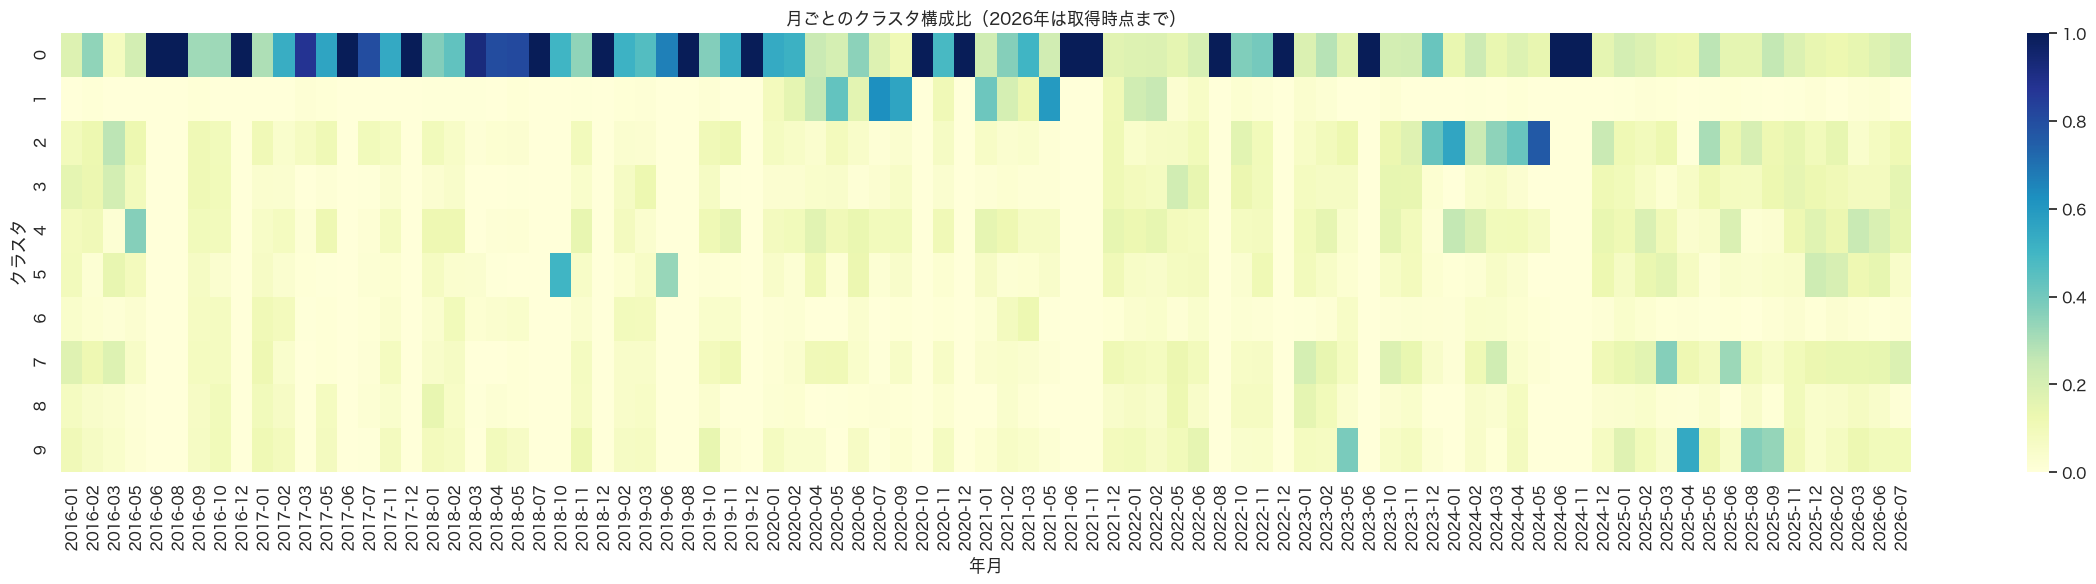

In [7]:
monthly_counts = pd.crosstab(assignments['month'], assignments['cluster'])
monthly_ratio = pd.crosstab(assignments['month'], assignments['cluster'], normalize='index')
display(monthly_counts)
plt.figure(figsize=(24, 6))
sns.heatmap(monthly_ratio.T, cmap='YlGnBu')
plt.title('月ごとのクラスタ構成比（2026年は取得時点まで）')
plt.xlabel('年月')
plt.ylabel('クラスタ')
plt.tight_layout();

## 6. 人手によるラベル調整

代表発言を確認し、必要なクラスタだけ名称を上書きしてください。

In [8]:
MANUAL_CLUSTER_LABELS = {
    # 0: '社会保障・医療',
    # 1: '外交・安全保障',
}
assignments, summary = apply_manual_labels(assignments, summary, MANUAL_CLUSTER_LABELS)
display(summary[['cluster', 'cluster_label', 'count', 'ratio', 'top_terms']].style.format({'ratio': '{:.1%}'}))

,cluster,cluster_label,count,ratio,top_terms
0,0,先程・答え・報告,23454,34.6%,先程 | 答え | 報告 | 事実 | 承知 | 判断 | 認識 | 委員会 | 文書 | 委員長 | 検討 | 理解
1,1,感染・接種・ワクチン,4036,5.9%,感染 | 接種 | ワクチン | 検査 | 医療 | 対策 | 状況 | 体制 | 拡大 | 感染 拡大 | コロナ | 感染症
2,2,議論・政治・自民党,6268,9.2%,議論 | 政治 | 自民党 | 議員 | 国民 | 資金 | 政治 資金 | 政党 | 選挙 | 総裁 | 政策 | 団体
3,3,経済・賃金・政策,4430,6.5%,経済 | 賃金 | 政策 | 成長 | 物価 | 賃上げ | 企業 | 財政 | 投資 | 金融 | 金利 | 日本
4,4,支援・地域・取り組み,8286,12.2%,支援 | 地域 | 取り組み | 事業 | 自治体 | 状況 | 地方 | 活用 | 整備 | 対策 | 災害 | 事業者
5,5,予算・年度・補正,3705,5.5%,予算 | 年度 | 補正 | 補正 予算 | 令和 | 令和 年度 | 計上 | 予算 委員会 | 基金 | 委員会 | 審議 | 対策
6,6,調査・結果・調査 結果,3076,4.5%,調査 | 結果 | 調査 結果 | 委員会 | 報告 | 統計 | 調査 調査 | 事案 | データ | 公表 | 先程 | 第三者
7,7,負担・制度・子供,6018,8.9%,負担 | 制度 | 子供 | 財源 | 子育て | 軽減 | 社会保障 | 支援 | 給付 | 教育 | 無償化 | 消費税
8,8,安全・安全 保障・保障,3523,5.2%,安全 | 安全 保障 | 保障 | 自衛隊 | 防衛 | 我が国 | 攻撃 | 米軍 | 基地 | ミサイル | 能力 | 日米
9,9,日本・アメリカ・世界,5086,7.5%,日本 | アメリカ | 世界 | 会談 | 交渉 | 我が国 | 日米 | 首脳 | 国際 | 中国 | 米国 | トランプ大統領


## 7. CSV出力と最終検証

In [9]:
assert len(assignments) + len(zero_vector_records) == 68948
assert assignments['speechID'].is_unique
assert assignments['cluster'].notna().all()
assert set(assignments['cluster']) == set(range(10))
assert summary['count'].sum() == len(assignments)
export_results(assignments, summary, OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
zero_vector_records.to_csv(OUTPUT_DIR / 'excluded_zero_vectors.csv', index=False, encoding='utf-8-sig')
monthly_counts.to_csv(OUTPUT_DIR / 'monthly_cluster_counts.csv', encoding='utf-8-sig')
monthly_ratio.to_csv(OUTPUT_DIR / 'monthly_cluster_ratios.csv', encoding='utf-8-sig')
assert len(pd.read_csv(OUTPUT_DIR / 'speech_clusters.csv')) == len(assignments)
assert len(pd.read_csv(OUTPUT_DIR / 'excluded_zero_vectors.csv')) == len(zero_vector_records)
assert len(pd.read_csv(OUTPUT_DIR / 'cluster_summary.csv')) == 10
print(f'出力先: {OUTPUT_DIR}')
print(f'検証完了: 元{len(source_df):,}件、ゼロベクトル除外{len(zero_vector_records):,}件、学習対象{len(assignments):,}件、10クラスタ')

出力先: /Users/tasskkiu2/kokkai/analysis/clustering_2016_2026_nouns
検証完了: 元68,948件、ゼロベクトル除外1,066件、学習対象67,882件、10クラスタ
